# Household Electric Power Consumption Forecasting

## DeepFabric Analytics Engineer Assessment

**Objective:** Analyze household electricity consumption data, identify trends and seasonality, engineer time-series features, and develop forecasting models to predict electricity consumption across multiple horizons.

### Project Workflow

1. Data loading and inspection
2. Data cleaning and preprocessing
3. Exploratory Data Analysis (EDA)
4. Feature engineering
5. Forecasting model development
6. Model evaluation and comparison
7. Forecast generation and export
8. API integration and actionable insights


In [36]:
print("Python notebook is working!")

Python notebook is working!


In [37]:
print("Python notebook is working!")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("All libraries imported successfully!")

Python notebook is working!
Pandas: 3.0.6
NumPy: 2.5.4
All libraries imported successfully!


In [38]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "household_power_consumption.txt"

print("Dataset exists:", DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(
    DATA_PATH,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset shape:", df.shape)
display(df.head())
print(df.dtypes)

Dataset exists: True
Dataset shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


Date                         str
Time                         str
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object


In [39]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df) * 100).round(2),
    "Data Type": df.dtypes.astype(str)
})

display(missing_summary)

print("Duplicate rows:", df.duplicated().sum())
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

,Missing Values,Missing Percentage,Data Type
Date,0,0.00,str
Time,0,0.00,str
Global_active_power,25979,1.25,float64
Global_reactive_power,25979,1.25,float64
Voltage,25979,1.25,float64
Global_intensity,25979,1.25,float64
Sub_metering_1,25979,1.25,float64
Sub_metering_2,25979,1.25,float64
Sub_metering_3,25979,1.25,float64


Duplicate rows: 0
Total rows: 2075259
Total columns: 9


In [40]:
df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

df = df.drop(columns=["Date", "Time"])
df = df.set_index("datetime")
df = df.sort_index()

print("Dataset shape:", df.shape)
print("Start date:", df.index.min())
print("End date:", df.index.max())
print("Datetime index:", df.index.dtype)
print("Chronologically sorted:", df.index.is_monotonic_increasing)

display(df.head())

Dataset shape: (2075259, 7)
Start date: 2006-12-16 17:24:00
End date: 2010-11-26 21:02:00
Datetime index: datetime64[us]
Chronologically sorted: True


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [41]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_summary)

print("Total missing cells:", df.isnull().sum().sum())
print("Rows containing missing values:", df.isnull().any(axis=1).sum())
print("Total rows:", len(df))

,Missing Values,Missing Percentage
Global_active_power,25979,1.25
Global_reactive_power,25979,1.25
Voltage,25979,1.25
Global_intensity,25979,1.25
Sub_metering_1,25979,1.25
Sub_metering_2,25979,1.25
Sub_metering_3,25979,1.25


Total missing cells: 181853
Rows containing missing values: 25979
Total rows: 2075259


In [42]:
df_clean = df.copy()

df_clean = df_clean.interpolate(method="time", limit_area="inside")

print("Missing values before:", df.isnull().sum().sum())
print("Missing values after:", df_clean.isnull().sum().sum())
print("Cleaned dataset shape:", df_clean.shape)

display(df_clean.head())

Missing values before: 181853
Missing values after: 0
Cleaned dataset shape: (2075259, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [43]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Global_active_power,2075259.0,1.090280,1.052628,0.076,0.310,0.614000,1.528,11.122
Global_reactive_power,2075259.0,0.123649,0.112419,0.000,0.048,0.100000,0.194,1.390
Voltage,2075259.0,240.832785,3.237763,223.200,238.990,241.000000,242.870,254.150
Global_intensity,2075259.0,4.621481,4.424361,0.200,1.400,2.751585,6.400,48.400
Sub_metering_1,2075259.0,1.109485,6.115843,0.000,0.000,0.000000,0.000,88.000
Sub_metering_2,2075259.0,1.289229,5.786613,0.000,0.000,0.000000,1.000,80.000
Sub_metering_3,2075259.0,6.442386,8.415860,0.000,0.000,1.000000,17.000,31.000


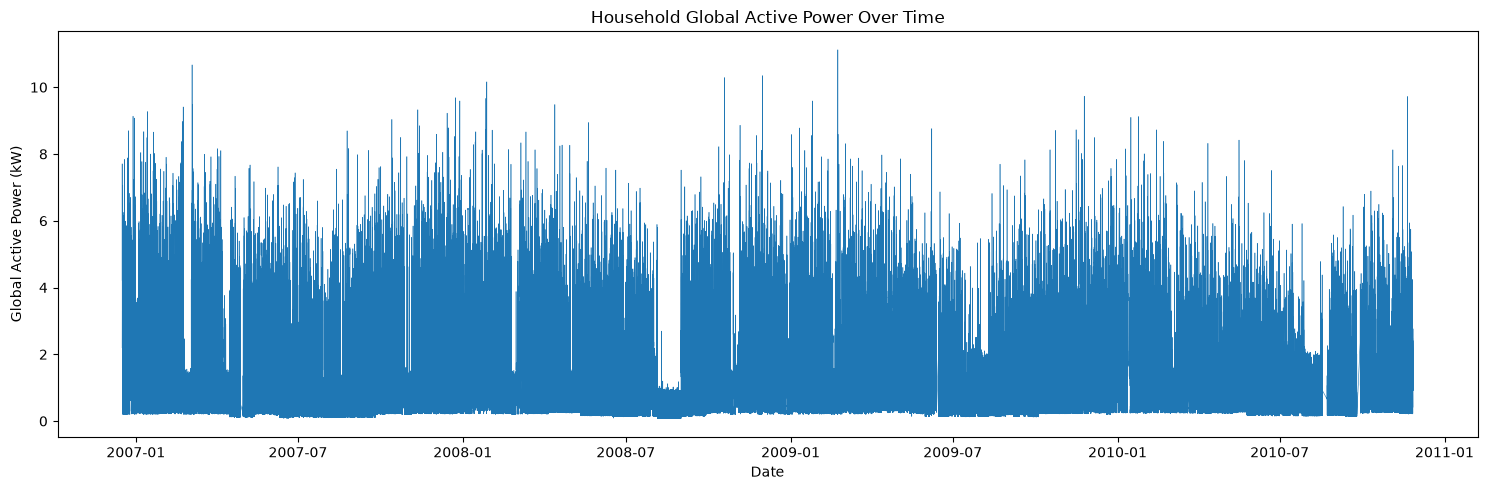

In [44]:
plt.figure(figsize=(15, 5))
plt.plot(df_clean.index, df_clean["Global_active_power"], linewidth=0.4)
plt.title("Household Global Active Power Over Time")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.tight_layout()
plt.show()

,Average_Power_kW,Energy_Consumption_kWh
datetime,,
2006-12-16,3.053475,20.152933
2006-12-17,2.354486,56.507667
2006-12-18,1.530435,36.730433
2006-12-19,1.157079,27.769900
2006-12-20,1.545658,37.095800


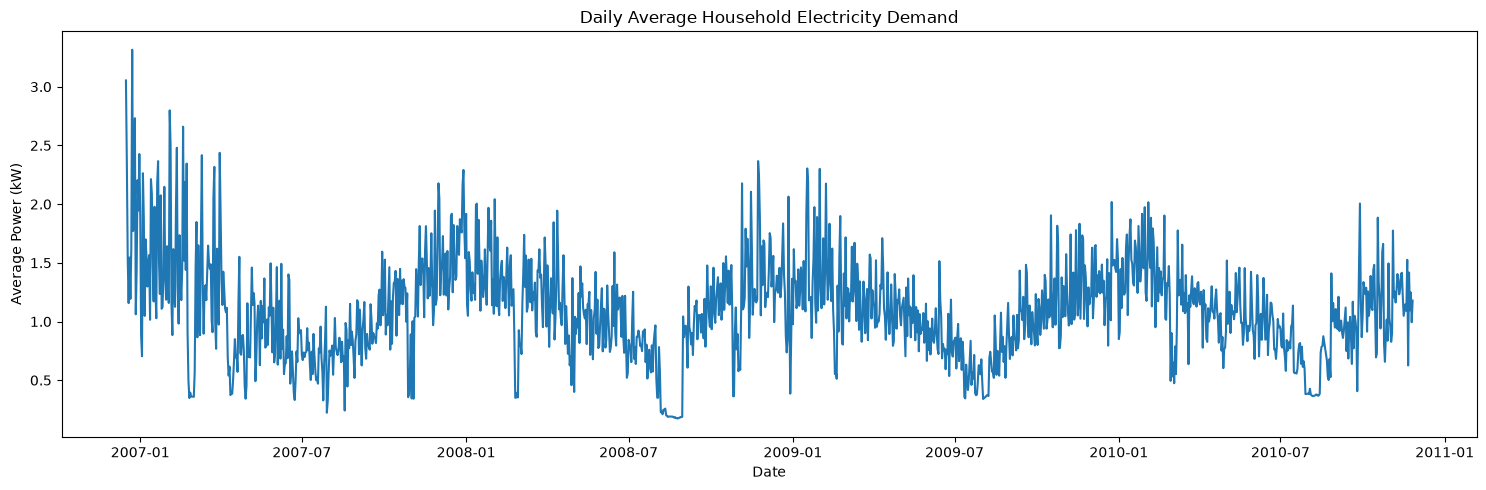

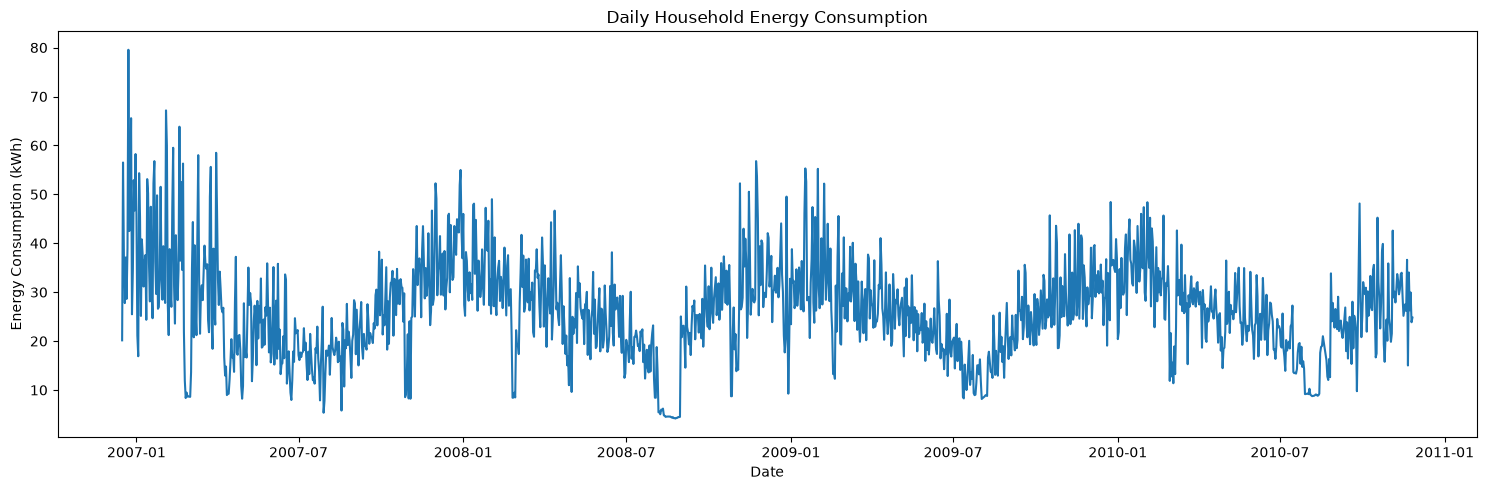

In [45]:
daily_data = pd.DataFrame({
    "Average_Power_kW": df_clean["Global_active_power"].resample("D").mean(),
    "Energy_Consumption_kWh": df_clean["Global_active_power"].resample("D").sum() / 60
})

display(daily_data.head())

plt.figure(figsize=(15, 5))
plt.plot(daily_data.index, daily_data["Average_Power_kW"])
plt.title("Daily Average Household Electricity Demand")
plt.xlabel("Date")
plt.ylabel("Average Power (kW)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
plt.plot(daily_data.index, daily_data["Energy_Consumption_kWh"])
plt.title("Daily Household Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (kWh)")
plt.tight_layout()
plt.show()

datetime
0     0.663418
1     0.544698
2     0.486809
3     0.451589
4     0.450522
5     0.460220
6     0.793647
7     1.494386
8     1.453509
9     1.326026
10    1.256255
11    1.242120
12    1.203516
13    1.141929
14    1.081551
15    0.991351
16    0.950159
17    1.055458
18    1.322805
19    1.724749
20    1.889776
21    1.868581
22    1.408790
23    0.903677
Name: Global_active_power, dtype: float64

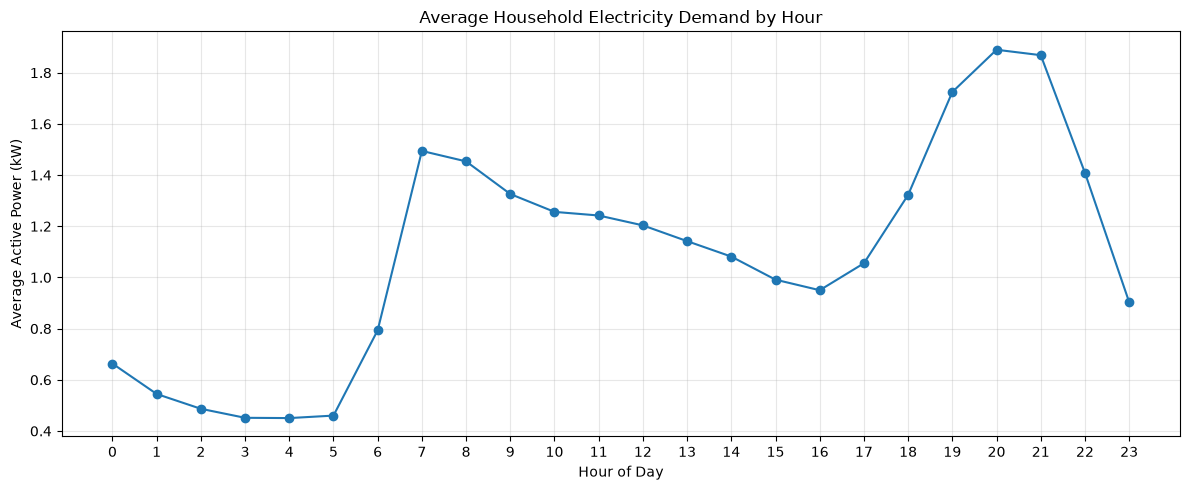

In [46]:
hourly_profile = df_clean.groupby(df_clean.index.hour)["Global_active_power"].mean()

display(hourly_profile)

plt.figure(figsize=(12, 5))
plt.plot(hourly_profile.index, hourly_profile.values, marker="o")
plt.title("Average Household Electricity Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Monday       1.001749
Tuesday      1.074770
Wednesday    1.085026
Thursday     0.982072
Friday       1.042086
Saturday     1.233651
Sunday       1.213079
Name: Global_active_power, dtype: float64

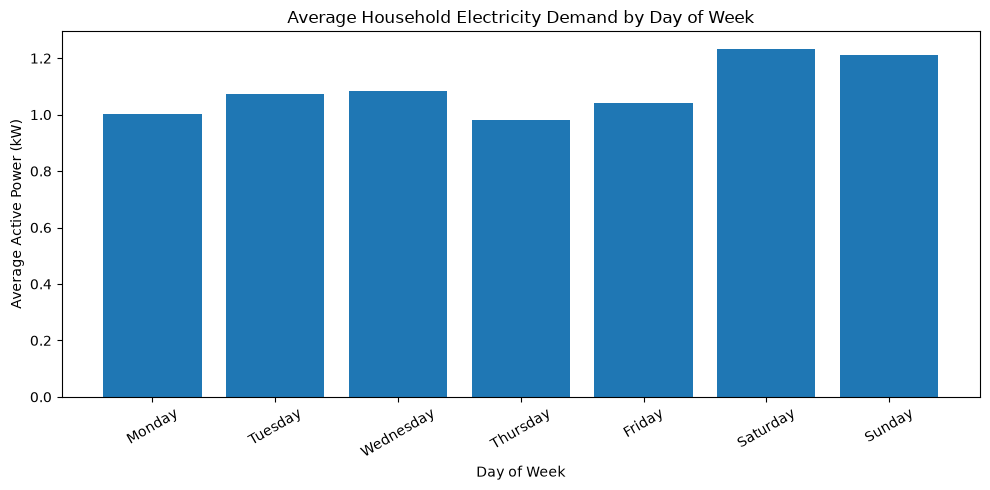

In [47]:
weekday_profile = df_clean.groupby(
    df_clean.index.dayofweek
)["Global_active_power"].mean()

weekday_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_profile.index = weekday_names

display(weekday_profile)

plt.figure(figsize=(10, 5))
plt.bar(weekday_profile.index, weekday_profile.values)
plt.title("Average Household Electricity Demand by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Active Power (kW)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [48]:
daily_counts = df_clean["Global_active_power"].resample("D").count()

print("Expected readings per complete day:", 1440)
print("Minimum readings in a day:", daily_counts.min())
print("Maximum readings in a day:", daily_counts.max())
print("Days with fewer than 1440 readings:", (daily_counts < 1440).sum())
print("Total calendar days:", len(daily_counts))

display(daily_counts[daily_counts < 1440].head(10))

Expected readings per complete day: 1440
Minimum readings in a day: 396
Maximum readings in a day: 1440
Days with fewer than 1440 readings: 2
Total calendar days: 1442


datetime
2006-12-16     396
2010-11-26    1263
Name: Global_active_power, dtype: int64

In [49]:
daily_data = pd.DataFrame({
    "Average_Power_kW": df_clean["Global_active_power"].resample("D").mean(),
    "Energy_Consumption_kWh": df_clean["Global_active_power"].resample("D").sum() / 60,
    "Readings": df_clean["Global_active_power"].resample("D").count()
})

daily_complete = daily_data.loc[daily_data["Readings"] == 1440].copy()

print("All calendar days:", len(daily_data))
print("Complete days:", len(daily_complete))
print("Incomplete days excluded:", len(daily_data) - len(daily_complete))

display(daily_complete.head())

All calendar days: 1442
Complete days: 1440
Incomplete days excluded: 2


,Average_Power_kW,Energy_Consumption_kWh,Readings
datetime,,,
2006-12-17,2.354486,56.507667,1440
2006-12-18,1.530435,36.730433,1440
2006-12-19,1.157079,27.769900,1440
2006-12-20,1.545658,37.095800,1440
2006-12-21,1.192440,28.618567,1440


In [50]:
daily_series = daily_complete["Energy_Consumption_kWh"].copy()

split_index = int(len(daily_series) * 0.8)

train_daily = daily_series.iloc[:split_index]
test_daily = daily_series.iloc[split_index:]

baseline_predictions = test_daily.shift(1)
baseline_predictions.iloc[0] = train_daily.iloc[-1]

errors = test_daily.to_numpy() - baseline_predictions.to_numpy()

mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors ** 2))

print("Training days:", len(train_daily))
print("Testing days:", len(test_daily))
print("Baseline MAE:", round(mae, 3), "kWh")
print("Baseline RMSE:", round(rmse, 3), "kWh")

Training days: 1152
Testing days: 288
Baseline MAE: 4.922 kWh
Baseline RMSE: 6.877 kWh


In [51]:
import sys
import sklearn
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Python executable:", sys.executable)
print("Scikit-learn version:", sklearn.__version__)
print("Imports successful")

Python executable: d:\DF_Analytics_2026_Assessment_DheerajKumar\.venv\Scripts\python.exe
Scikit-learn version: 1.9.1
Imports successful


In [52]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Linear Regression imported successfully")

Linear Regression imported successfully


In [53]:
model_data = daily_complete[["Energy_Consumption_kWh"]].copy()

for lag in [1, 2, 3, 7, 14, 28]:
    model_data[f"lag_{lag}"] = model_data["Energy_Consumption_kWh"].shift(lag)

model_data["day_of_week"] = model_data.index.dayofweek
model_data["month"] = model_data.index.month
model_data["day_of_year"] = model_data.index.dayofyear

model_data = model_data.dropna()

print("Model dataset shape:", model_data.shape)
display(model_data.head())

Model dataset shape: (1412, 10)


,Energy_Consumption_kWh,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,day_of_week,month,day_of_year
datetime,,,,,,,,,,
2007-01-14,50.183817,53.113567,24.354933,37.586567,40.793667,58.236600,56.507667,6,1,14
2007-01-15,35.811300,50.183817,53.113567,24.354933,37.356000,45.816733,36.730433,0,1,15
2007-01-16,28.106733,35.811300,50.183817,53.113567,31.150900,21.153933,27.769900,1,1,16
2007-01-17,47.461467,28.106733,35.811300,50.183817,35.913333,16.900900,37.095800,2,1,17
2007-01-18,30.357700,47.461467,28.106733,35.811300,37.586567,54.323533,28.618567,3,1,18


In [54]:
print("daily_complete exists:", "daily_complete" in globals())
print("df_clean exists:", "df_clean" in globals())
print("daily_data exists:", "daily_data" in globals())

daily_complete exists: True
df_clean exists: True
daily_data exists: True


In [55]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "household_power_consumption.txt"

df = pd.read_csv(DATA_PATH, sep=";", na_values=["?"], low_memory=False)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

df = df.drop(columns=["Date", "Time"])
df = df.set_index("datetime").sort_index()

df_clean = df.interpolate(method="time", limit_area="inside")

print("Dataset shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Start date:", df_clean.index.min())
print("End date:", df_clean.index.max())

Dataset shape: (2075259, 7)
Remaining missing values: 0
Start date: 2006-12-16 17:24:00
End date: 2010-11-26 21:02:00


In [56]:
daily_data = pd.DataFrame({
    "Average_Power_kW": df_clean["Global_active_power"].resample("D").mean(),
    "Energy_Consumption_kWh": df_clean["Global_active_power"].resample("D").sum() / 60,
    "Readings": df_clean["Global_active_power"].resample("D").count()
})

daily_complete = daily_data.loc[daily_data["Readings"] == 1440].copy()

print("All calendar days:", len(daily_data))
print("Complete days:", len(daily_complete))
print("Incomplete days excluded:", len(daily_data) - len(daily_complete))

display(daily_complete.head())

All calendar days: 1442
Complete days: 1440
Incomplete days excluded: 2


,Average_Power_kW,Energy_Consumption_kWh,Readings
datetime,,,
2006-12-17,2.354486,56.507667,1440
2006-12-18,1.530435,36.730433,1440
2006-12-19,1.157079,27.769900,1440
2006-12-20,1.545658,37.095800,1440
2006-12-21,1.192440,28.618567,1440


In [57]:
model_data = daily_complete[["Energy_Consumption_kWh"]].copy()

for lag in [1, 2, 3, 7, 14, 28]:
    model_data[f"lag_{lag}"] = model_data["Energy_Consumption_kWh"].shift(lag)

model_data["day_of_week"] = model_data.index.dayofweek
model_data["month"] = model_data.index.month
model_data["day_of_year"] = model_data.index.dayofyear

model_data = model_data.dropna()

print("Model dataset shape:", model_data.shape)
print("Feature columns:", model_data.columns.tolist())
display(model_data.head())

Model dataset shape: (1412, 10)
Feature columns: ['Energy_Consumption_kWh', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28', 'day_of_week', 'month', 'day_of_year']


,Energy_Consumption_kWh,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,day_of_week,month,day_of_year
datetime,,,,,,,,,,
2007-01-14,50.183817,53.113567,24.354933,37.586567,40.793667,58.236600,56.507667,6,1,14
2007-01-15,35.811300,50.183817,53.113567,24.354933,37.356000,45.816733,36.730433,0,1,15
2007-01-16,28.106733,35.811300,50.183817,53.113567,31.150900,21.153933,27.769900,1,1,16
2007-01-17,47.461467,28.106733,35.811300,50.183817,35.913333,16.900900,37.095800,2,1,17
2007-01-18,30.357700,47.461467,28.106733,35.811300,37.586567,54.323533,28.618567,3,1,18


In [58]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

X = model_data.drop(columns=["Energy_Consumption_kWh"])
y = model_data["Energy_Consumption_kWh"]

split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", X_train.index.min(), "to", X_train.index.max())
print("Testing period:", X_test.index.min(), "to", X_test.index.max())

Training rows: 1129
Testing rows: 283
Training period: 2007-01-14 00:00:00 to 2010-02-15 00:00:00
Testing period: 2010-02-16 00:00:00 to 2010-11-25 00:00:00


In [59]:
model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Model: Linear Regression")
print("MAE:", round(mae, 3), "kWh")
print("RMSE:", round(rmse, 3), "kWh")

Model: Linear Regression
MAE: 4.464 kWh
RMSE: 6.139 kWh


In [89]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

tscv = TimeSeriesSplit(n_splits=5)

mae_scores = []
rmse_scores = []

for train_idx, test_idx in tscv.split(X):
    X_train_fold = X.iloc[train_idx]
    X_test_fold = X.iloc[test_idx]

    y_train_fold = y.iloc[train_idx]
    y_test_fold = y.iloc[test_idx]

    model = LinearRegression()
    model.fit(X_train_fold, y_train_fold)

    predictions = model.predict(X_test_fold)

    mae_scores.append(mean_absolute_error(y_test_fold, predictions))
    rmse_scores.append(
        np.sqrt(mean_squared_error(y_test_fold, predictions))
    )

print("5-Fold Time Series Backtesting")
print("Average MAE:", round(np.mean(mae_scores), 3), "kWh")
print("Average RMSE:", round(np.mean(rmse_scores), 3), "kWh")

5-Fold Time Series Backtesting
Average MAE: 5.136 kWh
Average RMSE: 6.721 kWh


In [86]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

print("Model: Random Forest")
print("MAE:", round(rf_mae, 3), "kWh")
print("RMSE:", round(rf_rmse, 3), "kWh")

Model: Random Forest
MAE: 4.204 kWh
RMSE: 5.835 kWh


In [87]:
comparison = pd.DataFrame({
    "Model": ["Naive Baseline", "Linear Regression", "Random Forest"],
    "MAE (kWh)": [4.922, 4.464, rf_mae],
    "RMSE (kWh)": [6.877, 6.139, rf_rmse]
})

display(comparison)

,Model,MAE (kWh),RMSE (kWh)
0,Naive Baseline,4.922000,6.877000
1,Linear Regression,4.464000,6.139000
2,Random Forest,4.204311,5.834973


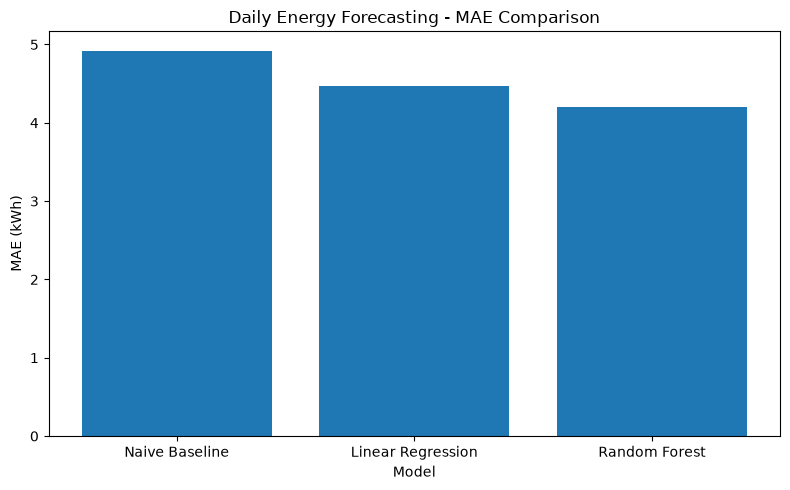

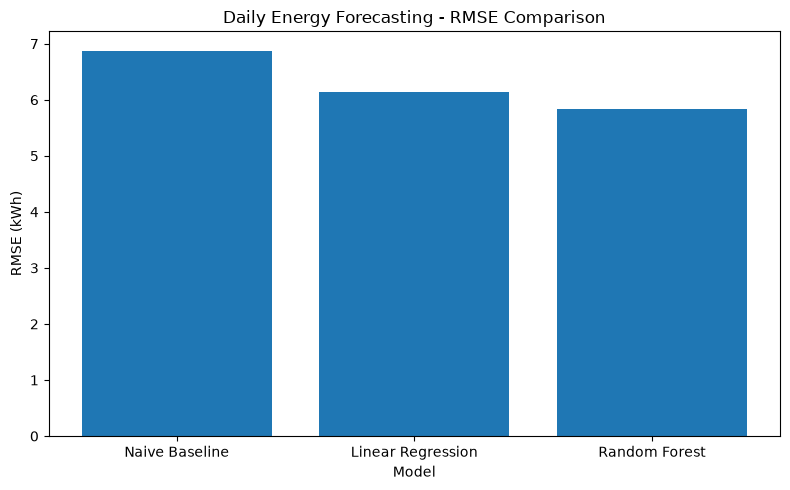

In [88]:
import matplotlib.pyplot as plt

models = ["Naive Baseline", "Linear Regression", "Random Forest"]
mae_values = [4.922, 4.464, rf_mae]
rmse_values = [6.877, 6.139, rf_rmse]

plt.figure(figsize=(8, 5))
plt.bar(models, mae_values)
plt.title("Daily Energy Forecasting - MAE Comparison")
plt.ylabel("MAE (kWh)")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(models, rmse_values)
plt.title("Daily Energy Forecasting - RMSE Comparison")
plt.ylabel("RMSE (kWh)")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

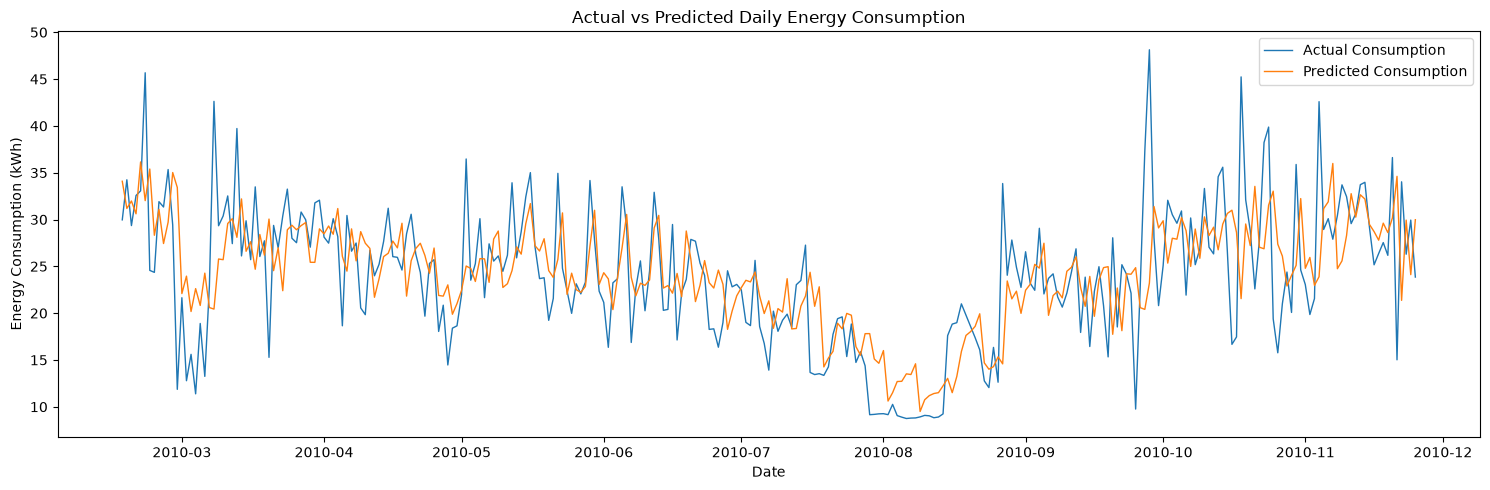

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.plot(y_test.index, y_test, label="Actual Consumption", linewidth=1)
plt.plot(y_test.index, y_pred, label="Predicted Consumption", linewidth=1)
plt.title("Actual vs Predicted Daily Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

Mean error: -0.338 kWh
Largest overprediction: 21.563 kWh
Largest underprediction: 24.918 kWh


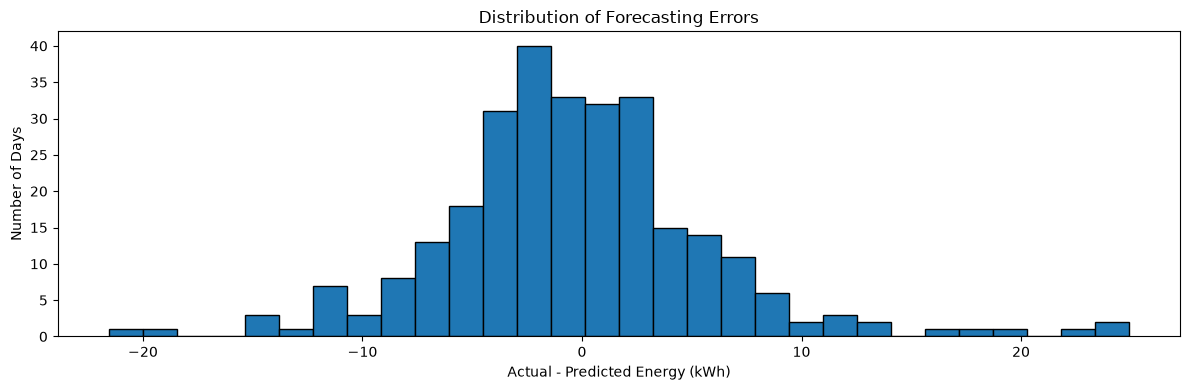

In [61]:
residuals = y_test - y_pred

print("Mean error:", round(residuals.mean(), 3), "kWh")
print("Largest overprediction:", round((y_pred - y_test).max(), 3), "kWh")
print("Largest underprediction:", round((y_test - y_pred).max(), 3), "kWh")

plt.figure(figsize=(12, 4))
plt.hist(residuals, bins=30, edgecolor="black")
plt.title("Distribution of Forecasting Errors")
plt.xlabel("Actual - Predicted Energy (kWh)")
plt.ylabel("Number of Days")
plt.tight_layout()
plt.show()

In [62]:
minute_data = df_clean[["Global_active_power"]].copy()

for lag in [1, 2, 3, 5, 10, 15, 30, 60]:
    minute_data[f"lag_{lag}"] = minute_data["Global_active_power"].shift(lag)

minute_data["hour"] = minute_data.index.hour
minute_data["minute"] = minute_data.index.minute
minute_data["day_of_week"] = minute_data.index.dayofweek

minute_data = minute_data.dropna()

print("Minute-level model dataset shape:", minute_data.shape)
display(minute_data.head())

Minute-level model dataset shape: (2075199, 12)


,Global_active_power,lag_1,lag_2,lag_3,lag_5,lag_10,lag_15,lag_30,lag_60,hour,minute,day_of_week
datetime,,,,,,,,,,,,
2006-12-16 18:24:00,3.452,2.926,2.934,2.940,2.852,2.388,4.464,2.720,4.216,18,24,5
2006-12-16 18:25:00,4.870,3.452,2.926,2.934,2.928,4.598,3.396,3.758,5.360,18,25,5
2006-12-16 18:26:00,4.868,4.870,3.452,2.926,2.940,4.524,3.090,4.342,5.374,18,26,5
2006-12-16 18:27:00,4.866,4.868,4.870,3.452,2.934,4.202,3.730,4.512,5.388,18,27,5
2006-12-16 18:28:00,3.176,4.866,4.868,4.870,2.926,4.472,2.308,4.058,3.666,18,28,5


In [63]:
split_index = int(len(minute_data) * 0.8)

train_minute = minute_data.iloc[:split_index]
test_minute = minute_data.iloc[split_index:]

train_sample = train_minute.iloc[::10].copy()

feature_columns = [
    "lag_1", "lag_2", "lag_3", "lag_5",
    "lag_10", "lag_15", "lag_30", "lag_60",
    "hour", "minute", "day_of_week"
]

X_train_minute = train_sample[feature_columns]
y_train_minute = train_sample["Global_active_power"]

X_test_minute = test_minute[feature_columns]
y_test_minute = test_minute["Global_active_power"]

print("Training sample rows:", len(X_train_minute))
print("Testing rows:", len(X_test_minute))
print("Training period:", train_sample.index.min(), "to", train_sample.index.max())
print("Testing period:", test_minute.index.min(), "to", test_minute.index.max())

Training sample rows: 166016
Testing rows: 415040
Training period: 2006-12-16 18:24:00 to 2010-02-11 15:34:00
Testing period: 2010-02-11 15:43:00 to 2010-11-26 21:02:00


In [64]:
minute_model = LinearRegression()

minute_model.fit(X_train_minute, y_train_minute)

minute_predictions = minute_model.predict(X_test_minute)

minute_mae = mean_absolute_error(y_test_minute, minute_predictions)
minute_rmse = np.sqrt(mean_squared_error(y_test_minute, minute_predictions))

print("Model: Minute-level Linear Regression")
print("MAE:", round(minute_mae, 4), "kW")
print("RMSE:", round(minute_rmse, 4), "kW")

Model: Minute-level Linear Regression
MAE: 0.0832 kW
RMSE: 0.216 kW


In [65]:
latest_values = df_clean["Global_active_power"].tail(60).to_numpy().tolist()
last_timestamp = df_clean.index[-1]

forecast_rows = []

for step in range(1, 61):
    forecast_time = last_timestamp + pd.Timedelta(minutes=step)

    features = pd.DataFrame([{
        "lag_1": latest_values[-1],
        "lag_2": latest_values[-2],
        "lag_3": latest_values[-3],
        "lag_5": latest_values[-5],
        "lag_10": latest_values[-10],
        "lag_15": latest_values[-15],
        "lag_30": latest_values[-30],
        "lag_60": latest_values[-60],
        "hour": forecast_time.hour,
        "minute": forecast_time.minute,
        "day_of_week": forecast_time.dayofweek
    }])

    prediction = minute_model.predict(features[feature_columns])[0]
    prediction = max(0, prediction)

    latest_values.append(prediction)

    forecast_rows.append({
        "datetime": forecast_time,
        "Predicted_Global_active_power_kW": prediction
    })

forecast_60_minutes = pd.DataFrame(forecast_rows).set_index("datetime")

print("Forecast horizon:", len(forecast_60_minutes), "minutes")
display(forecast_60_minutes.head(10))

Forecast horizon: 60 minutes


,Predicted_Global_active_power_kW
datetime,
2010-11-26 21:03:00,0.945859
2010-11-26 21:04:00,0.960214
2010-11-26 21:05:00,0.983572
2010-11-26 21:06:00,0.996353
2010-11-26 21:07:00,1.004209
2010-11-26 21:08:00,1.014281
2010-11-26 21:09:00,1.022133
2010-11-26 21:10:00,1.031275
2010-11-26 21:11:00,1.040269


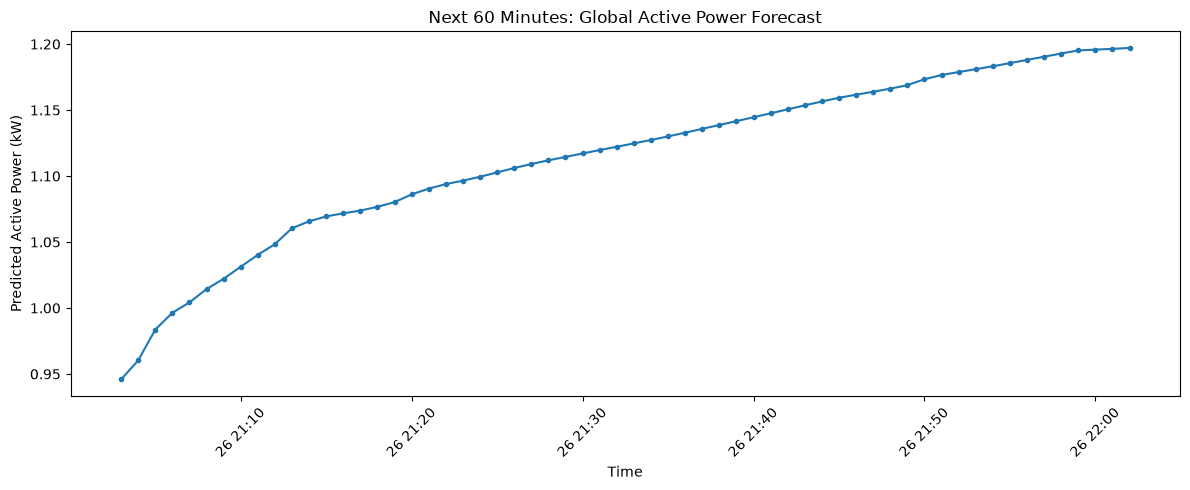

In [66]:
plt.figure(figsize=(12, 5))
plt.plot(
    forecast_60_minutes.index,
    forecast_60_minutes["Predicted_Global_active_power_kW"],
    marker=".",
    linewidth=1.5
)
plt.title("Next 60 Minutes: Global Active Power Forecast")
plt.xlabel("Time")
plt.ylabel("Predicted Active Power (kW)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [67]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Output folder:", OUTPUT_DIR)
print("Folder exists:", OUTPUT_DIR.exists())
print("\nFiles in outputs folder:")

for file in OUTPUT_DIR.iterdir():
    print(file.name)

Project folder: d:\DF_Analytics_2026_Assessment_DheerajKumar
Output folder: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs
Folder exists: True

Files in outputs folder:
energy_consumption_next_24_hours.csv
energy_consumption_next_7_days.csv
global_active_power_next_60_minutes.csv
hourly_energy_model.joblib
sub_metering_3_next_24_hours.csv


In [68]:
print("Forecast available:", "forecast_60_minutes" in globals())

Forecast available: True


In [69]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "global_active_power_next_60_minutes.csv"

forecast_60_minutes.to_csv(output_file, index=True)

print("Forecast saved successfully!")
print("File exists:", output_file.exists())
print("Number of predictions:", len(forecast_60_minutes))
print("Saved location:", output_file)

Forecast saved successfully!
File exists: True
Number of predictions: 60
Saved location: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs\global_active_power_next_60_minutes.csv


In [70]:
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "global_active_power_next_60_minutes.csv"

forecast_60_minutes.to_csv(output_file)

print("Forecast saved successfully!")
print("File exists:", output_file.exists())
print("Number of predictions:", len(forecast_60_minutes))
print("Saved location:", output_file)

Forecast saved successfully!
File exists: True
Number of predictions: 60
Saved location: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs\global_active_power_next_60_minutes.csv


In [90]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

global_power_hourly = df_clean["Global_active_power"].resample("h").mean()

power_model_data = pd.DataFrame({
    "Global_active_power": global_power_hourly
})

for lag in [1, 2, 3, 6, 12, 24, 48, 168]:
    power_model_data[f"lag_{lag}"] = power_model_data["Global_active_power"].shift(lag)

power_model_data["hour_of_day"] = power_model_data.index.hour
power_model_data["day_of_week"] = power_model_data.index.dayofweek
power_model_data["month"] = power_model_data.index.month

power_model_data = power_model_data.dropna()

X_power = power_model_data.drop(columns=["Global_active_power"])
y_power = power_model_data["Global_active_power"]

split_index_power = int(len(power_model_data) * 0.8)

X_train_power = X_power.iloc[:split_index_power]
y_train_power = y_power.iloc[:split_index_power]
X_test_power = X_power.iloc[split_index_power:]
y_test_power = y_power.iloc[split_index_power:]

global_power_model = LinearRegression()
global_power_model.fit(X_train_power, y_train_power)

test_predictions_power = global_power_model.predict(X_test_power)

power_mae = mean_absolute_error(y_test_power, test_predictions_power)
power_rmse = np.sqrt(mean_squared_error(y_test_power, test_predictions_power))

print("MAE:", round(power_mae, 4), "kW")
print("RMSE:", round(power_rmse, 4), "kW")

history = global_power_hourly.dropna().tail(168).tolist()
last_timestamp = global_power_hourly.dropna().index[-1]

forecast_rows_power = []

for step in range(1, 25):
    forecast_time = last_timestamp + pd.Timedelta(hours=step)

    features_power = {
        "lag_1": history[-1],
        "lag_2": history[-2],
        "lag_3": history[-3],
        "lag_6": history[-6],
        "lag_12": history[-12],
        "lag_24": history[-24],
        "lag_48": history[-48],
        "lag_168": history[-168],
        "hour_of_day": forecast_time.hour,
        "day_of_week": forecast_time.dayofweek,
        "month": forecast_time.month
    }

    input_power = pd.DataFrame([features_power], columns=X_power.columns)
    prediction_power = max(0.0, float(global_power_model.predict(input_power)[0]))

    history.append(prediction_power)

    forecast_rows_power.append({
        "datetime": forecast_time,
        "Predicted_Global_active_power_kW": prediction_power
    })

forecast_global_power_24h = pd.DataFrame(forecast_rows_power).set_index("datetime")

project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
output_dir = project_dir / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

output_file_power = output_dir / "global_active_power_next_24_hours.csv"
forecast_global_power_24h.to_csv(output_file_power)

print("Forecast rows:", len(forecast_global_power_24h))
print("File exists:", output_file_power.exists())
print("Saved location:", output_file_power)

display(forecast_global_power_24h.head())

MAE: 0.3584 kW
RMSE: 0.5067 kW
Forecast rows: 24
File exists: True
Saved location: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs\global_active_power_next_24_hours.csv


,Predicted_Global_active_power_kW
datetime,
2010-11-26 22:00:00,0.936998
2010-11-26 23:00:00,0.888323
2010-11-27 00:00:00,0.731595
2010-11-27 01:00:00,0.638534
2010-11-27 02:00:00,0.593647


In [71]:
required_variables = [
    "daily_complete",
    "model_data",
    "model",
    "X",
    "y"
]

for variable in required_variables:
    print(f"{variable}: {variable in globals()}")

daily_complete: True
model_data: True
model: True
X: True
y: True


In [72]:
hourly_data = pd.DataFrame({
    "Average_Power_kW": df_clean["Global_active_power"].resample("h").mean(),
    "Energy_Consumption_kWh": df_clean["Global_active_power"].resample("h").sum() / 60,
    "Readings": df_clean["Global_active_power"].resample("h").count()
})

hourly_complete = hourly_data.loc[hourly_data["Readings"] == 60].copy()

print("All hourly periods:", len(hourly_data))
print("Complete hours:", len(hourly_complete))
print("Incomplete hours excluded:", len(hourly_data) - len(hourly_complete))

display(hourly_complete.head())

All hourly periods: 34589
Complete hours: 34587
Incomplete hours excluded: 2


,Average_Power_kW,Energy_Consumption_kWh,Readings
datetime,,,
2006-12-16 18:00:00,3.632200,3.632200,60
2006-12-16 19:00:00,3.400233,3.400233,60
2006-12-16 20:00:00,3.268567,3.268567,60
2006-12-16 21:00:00,3.056467,3.056467,60
2006-12-16 22:00:00,2.200133,2.200133,60


In [73]:
hourly_model_data = hourly_complete[["Energy_Consumption_kWh"]].copy()

for lag in [1, 2, 3, 6, 12, 24, 48, 168]:
    hourly_model_data[f"lag_{lag}"] = hourly_model_data["Energy_Consumption_kWh"].shift(lag)

hourly_model_data["hour_of_day"] = hourly_model_data.index.hour
hourly_model_data["day_of_week"] = hourly_model_data.index.dayofweek
hourly_model_data["month"] = hourly_model_data.index.month

hourly_model_data = hourly_model_data.dropna()

print("Hourly model dataset shape:", hourly_model_data.shape)
display(hourly_model_data.head())

Hourly model dataset shape: (34419, 12)


,Energy_Consumption_kWh,lag_1,lag_2,lag_3,lag_6,lag_12,lag_24,lag_48,lag_168,hour_of_day,day_of_week,month
datetime,,,,,,,,,,,,
2006-12-23 18:00:00,3.879400,5.452533,4.349100,4.049100,2.928800,1.649367,2.686967,2.443300,3.632200,18,5,12
2006-12-23 19:00:00,4.117833,3.879400,5.452533,4.349100,3.406300,4.023367,3.938167,2.197133,3.400233,19,5,12
2006-12-23 20:00:00,4.181400,4.117833,3.879400,5.452533,3.757967,4.190833,3.536067,2.437367,3.268567,20,5,12
2006-12-23 21:00:00,3.288433,4.181400,4.117833,3.879400,4.049100,3.246400,4.548667,0.982267,3.056467,21,5,12
2006-12-23 22:00:00,4.327933,3.288433,4.181400,4.117833,4.349100,2.972167,3.065067,0.280267,2.200133,22,5,12


In [74]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

X_hourly = hourly_model_data.drop(columns=["Energy_Consumption_kWh"])
y_hourly = hourly_model_data["Energy_Consumption_kWh"]

split_index = int(len(hourly_model_data) * 0.8)

X_train_hourly = X_hourly.iloc[:split_index]
X_test_hourly = X_hourly.iloc[split_index:]
y_train_hourly = y_hourly.iloc[:split_index]
y_test_hourly = y_hourly.iloc[split_index:]

hourly_model = LinearRegression()
hourly_model.fit(X_train_hourly, y_train_hourly)

hourly_predictions = hourly_model.predict(X_test_hourly)
hourly_predictions = np.maximum(hourly_predictions, 0)

hourly_mae = mean_absolute_error(y_test_hourly, hourly_predictions)
hourly_rmse = np.sqrt(mean_squared_error(y_test_hourly, hourly_predictions))

print("Training samples:", len(X_train_hourly))
print("Testing samples:", len(X_test_hourly))
print("Training period:", X_train_hourly.index.min(), "to", X_train_hourly.index.max())
print("Testing period:", X_test_hourly.index.min(), "to", X_test_hourly.index.max())
print("Hourly Model MAE:", round(hourly_mae, 4), "kWh")
print("Hourly Model RMSE:", round(hourly_rmse, 4), "kWh")

Training samples: 27535
Testing samples: 6884
Training period: 2006-12-23 18:00:00 to 2010-02-13 00:00:00
Testing period: 2010-02-13 01:00:00 to 2010-11-26 20:00:00
Hourly Model MAE: 0.3584 kWh
Hourly Model RMSE: 0.5067 kWh


In [75]:
latest_hourly_values = hourly_complete["Energy_Consumption_kWh"].tail(168).tolist()
last_hourly_timestamp = hourly_complete.index[-1]

hourly_forecast_rows = []

for step in range(1, 25):
    forecast_time = last_hourly_timestamp + pd.Timedelta(hours=step)

    features = {
        "lag_1": latest_hourly_values[-1],
        "lag_2": latest_hourly_values[-2],
        "lag_3": latest_hourly_values[-3],
        "lag_6": latest_hourly_values[-6],
        "lag_12": latest_hourly_values[-12],
        "lag_24": latest_hourly_values[-24],
        "lag_48": latest_hourly_values[-48],
        "lag_168": latest_hourly_values[-168],
        "hour_of_day": forecast_time.hour,
        "day_of_week": forecast_time.dayofweek,
        "month": forecast_time.month
    }

    input_data = pd.DataFrame([features], columns=X_train_hourly.columns)
    prediction = hourly_model.predict(input_data)[0]
    prediction = max(0, prediction)

    latest_hourly_values.append(prediction)

    hourly_forecast_rows.append({
        "datetime": forecast_time,
        "Predicted_Energy_Consumption_kWh": prediction
    })

forecast_24_hours = pd.DataFrame(hourly_forecast_rows).set_index("datetime")

print("Forecast horizon:", len(forecast_24_hours), "hours")
print("Forecast starts:", forecast_24_hours.index.min())
print("Forecast ends:", forecast_24_hours.index.max())
display(forecast_24_hours)

Forecast horizon: 24 hours
Forecast starts: 2010-11-26 21:00:00
Forecast ends: 2010-11-27 20:00:00


,Predicted_Energy_Consumption_kWh
datetime,
2010-11-26 21:00:00,1.337618
2010-11-26 22:00:00,1.191874
2010-11-26 23:00:00,1.015862
2010-11-27 00:00:00,0.788237
2010-11-27 01:00:00,0.661882
2010-11-27 02:00:00,0.602719
2010-11-27 03:00:00,0.555951
2010-11-27 04:00:00,0.552573
2010-11-27 05:00:00,0.709702


In [76]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

hourly_forecast_file = OUTPUT_DIR / "energy_consumption_next_24_hours.csv"

forecast_24_hours.to_csv(hourly_forecast_file)

print("Forecast saved:", hourly_forecast_file.exists())
print("Number of predictions:", len(forecast_24_hours))
print("File location:", hourly_forecast_file)

Forecast saved: True
Number of predictions: 24
File location: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs\energy_consumption_next_24_hours.csv


In [77]:
submeter_hourly = pd.DataFrame({
    "Sub_metering_3": df_clean["Sub_metering_3"].resample("h").mean(),
    "Readings": df_clean["Sub_metering_3"].resample("h").count()
})

submeter_hourly = submeter_hourly.loc[
    submeter_hourly["Readings"] == 60,
    ["Sub_metering_3"]
]

print("Complete hourly observations:", len(submeter_hourly))
print("Missing values:", submeter_hourly["Sub_metering_3"].isna().sum())
display(submeter_hourly.head())

Complete hourly observations: 34587
Missing values: 0


,Sub_metering_3
datetime,
2006-12-16 18:00:00,16.866667
2006-12-16 19:00:00,16.683333
2006-12-16 20:00:00,16.783333
2006-12-16 21:00:00,17.216667
2006-12-16 22:00:00,4.433333


In [78]:
submeter_model_data = submeter_hourly.copy()

for lag in [1, 2, 3, 6, 12, 24, 48, 168]:
    submeter_model_data[f"lag_{lag}"] = submeter_model_data["Sub_metering_3"].shift(lag)

submeter_model_data["hour_of_day"] = submeter_model_data.index.hour
submeter_model_data["day_of_week"] = submeter_model_data.index.dayofweek
submeter_model_data["month"] = submeter_model_data.index.month

submeter_model_data = submeter_model_data.dropna()

print("Sub-metering model dataset shape:", submeter_model_data.shape)
display(submeter_model_data.head())

Sub-metering model dataset shape: (34419, 12)


,Sub_metering_3,lag_1,lag_2,lag_3,lag_6,lag_12,lag_24,lag_48,lag_168,hour_of_day,day_of_week,month
datetime,,,,,,,,,,,,
2006-12-23 18:00:00,17.350000,16.750000,17.716667,17.833333,9.566667,0.000000,3.900000,16.766667,16.866667,18,5,12
2006-12-23 19:00:00,17.466667,17.350000,16.750000,17.716667,17.616667,10.850000,17.266667,11.700000,16.683333,19,5,12
2006-12-23 20:00:00,17.416667,17.466667,17.350000,16.750000,17.716667,17.500000,17.016667,4.283333,16.783333,20,5,12
2006-12-23 21:00:00,5.666667,17.416667,17.466667,17.350000,17.833333,17.766667,16.750000,8.583333,17.216667,21,5,12
2006-12-23 22:00:00,0.000000,5.666667,17.416667,17.466667,17.716667,8.600000,0.000000,0.000000,4.433333,22,5,12


In [79]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

X_submeter = submeter_model_data.drop(columns=["Sub_metering_3"])
y_submeter = submeter_model_data["Sub_metering_3"]

split_index = int(len(submeter_model_data) * 0.8)

X_train_submeter = X_submeter.iloc[:split_index]
X_test_submeter = X_submeter.iloc[split_index:]
y_train_submeter = y_submeter.iloc[:split_index]
y_test_submeter = y_submeter.iloc[split_index:]

submeter_model = LinearRegression()
submeter_model.fit(X_train_submeter, y_train_submeter)

submeter_predictions = np.maximum(
    submeter_model.predict(X_test_submeter), 0
)

submeter_mae = mean_absolute_error(
    y_test_submeter, submeter_predictions
)

submeter_rmse = np.sqrt(
    mean_squared_error(y_test_submeter, submeter_predictions)
)

print("Training samples:", len(X_train_submeter))
print("Testing samples:", len(X_test_submeter))
print("Training period:", X_train_submeter.index.min(), "to", X_train_submeter.index.max())
print("Testing period:", X_test_submeter.index.min(), "to", X_test_submeter.index.max())
print("Sub-metering MAE:", round(submeter_mae, 4))
print("Sub-metering RMSE:", round(submeter_rmse, 4))

Training samples: 27535
Testing samples: 6884
Training period: 2006-12-23 18:00:00 to 2010-02-13 00:00:00
Testing period: 2010-02-13 01:00:00 to 2010-11-26 20:00:00
Sub-metering MAE: 4.008
Sub-metering RMSE: 5.3287


In [80]:
latest_submeter_values = submeter_hourly["Sub_metering_3"].tail(168).tolist()
last_submeter_timestamp = submeter_hourly.index[-1]

submeter_forecast_rows = []

for step in range(1, 25):
    forecast_time = last_submeter_timestamp + pd.Timedelta(hours=step)

    features = {
        "lag_1": latest_submeter_values[-1],
        "lag_2": latest_submeter_values[-2],
        "lag_3": latest_submeter_values[-3],
        "lag_6": latest_submeter_values[-6],
        "lag_12": latest_submeter_values[-12],
        "lag_24": latest_submeter_values[-24],
        "lag_48": latest_submeter_values[-48],
        "lag_168": latest_submeter_values[-168],
        "hour_of_day": forecast_time.hour,
        "day_of_week": forecast_time.dayofweek,
        "month": forecast_time.month
    }

    input_data = pd.DataFrame([features], columns=X_train_submeter.columns)
    prediction = max(0, submeter_model.predict(input_data)[0])

    latest_submeter_values.append(prediction)

    submeter_forecast_rows.append({
        "datetime": forecast_time,
        "Predicted_Sub_metering_3": prediction
    })

forecast_submeter_24h = pd.DataFrame(
    submeter_forecast_rows
).set_index("datetime")

print("Forecast horizon:", len(forecast_submeter_24h), "hours")
print("Forecast starts:", forecast_submeter_24h.index.min())
print("Forecast ends:", forecast_submeter_24h.index.max())

display(forecast_submeter_24h)

Forecast horizon: 24 hours
Forecast starts: 2010-11-26 21:00:00
Forecast ends: 2010-11-27 20:00:00


,Predicted_Sub_metering_3
datetime,
2010-11-26 21:00:00,3.727490
2010-11-26 22:00:00,4.362383
2010-11-26 23:00:00,3.878552
2010-11-27 00:00:00,3.231991
2010-11-27 01:00:00,2.888473
2010-11-27 02:00:00,2.737163
2010-11-27 03:00:00,2.474224
2010-11-27 04:00:00,2.360501
2010-11-27 05:00:00,4.674128


In [81]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

submeter_file = OUTPUT_DIR / "sub_metering_3_next_24_hours.csv"
forecast_submeter_24h.to_csv(submeter_file)

print("File saved:", submeter_file.exists())
print("Predictions saved:", len(forecast_submeter_24h))
print("Location:", submeter_file)

File saved: True
Predictions saved: 24
Location: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs\sub_metering_3_next_24_hours.csv


In [82]:
latest_daily_values = daily_complete["Energy_Consumption_kWh"].tail(28).tolist()
last_daily_timestamp = daily_complete.index[-1]

daily_forecast_rows = []

for step in range(1, 8):
    forecast_date = last_daily_timestamp + pd.Timedelta(days=step)

    features = {
        "lag_1": latest_daily_values[-1],
        "lag_2": latest_daily_values[-2],
        "lag_3": latest_daily_values[-3],
        "lag_7": latest_daily_values[-7],
        "lag_14": latest_daily_values[-14],
        "lag_28": latest_daily_values[-28],
        "day_of_week": forecast_date.dayofweek,
        "month": forecast_date.month,
        "day_of_year": forecast_date.dayofyear
    }

    input_data = pd.DataFrame([features], columns=X_train.columns)
    prediction = max(0, model.predict(input_data)[0])

    latest_daily_values.append(prediction)

    daily_forecast_rows.append({
        "date": forecast_date,
        "Predicted_Energy_Consumption_kWh": prediction
    })

forecast_7_days = pd.DataFrame(daily_forecast_rows).set_index("date")

print("Forecast horizon:", len(forecast_7_days), "days")
print("Forecast starts:", forecast_7_days.index.min())
print("Forecast ends:", forecast_7_days.index.max())

display(forecast_7_days)

Forecast horizon: 7 days
Forecast starts: 2010-11-26 00:00:00
Forecast ends: 2010-12-02 00:00:00


,Predicted_Energy_Consumption_kWh
date,
2010-11-26,26.733663
2010-11-27,31.594864
2010-11-28,29.208948
2010-11-29,26.795762
2010-11-30,25.907153
2010-12-01,27.409450
2010-12-02,28.225331


In [83]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

daily_forecast_file = OUTPUT_DIR / "energy_consumption_next_7_days.csv"
forecast_7_days.to_csv(daily_forecast_file)

print("File saved:", daily_forecast_file.exists())
print("Number of predictions:", len(forecast_7_days))
print("Saved location:", daily_forecast_file)

File saved: True
Number of predictions: 7
Saved location: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs\energy_consumption_next_7_days.csv


In [91]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

daily_power = df_clean["Global_active_power"].resample("D").mean()
daily_power = daily_power.dropna()

power_daily_model_data = pd.DataFrame({
    "Global_active_power": daily_power
})

for lag in [1, 2, 3, 7, 14, 28]:
    power_daily_model_data[f"lag_{lag}"] = (
        power_daily_model_data["Global_active_power"].shift(lag)
    )

power_daily_model_data["day_of_week"] = power_daily_model_data.index.dayofweek
power_daily_model_data["month"] = power_daily_model_data.index.month
power_daily_model_data["day_of_year"] = power_daily_model_data.index.dayofyear

power_daily_model_data = power_daily_model_data.dropna()

X_daily_power = power_daily_model_data.drop(columns=["Global_active_power"])
y_daily_power = power_daily_model_data["Global_active_power"]

split_daily_power = int(len(power_daily_model_data) * 0.8)

X_train_daily_power = X_daily_power.iloc[:split_daily_power]
y_train_daily_power = y_daily_power.iloc[:split_daily_power]

power_daily_model = LinearRegression()
power_daily_model.fit(X_train_daily_power, y_train_daily_power)

history_daily_power = daily_power.tail(28).tolist()
last_daily_timestamp = daily_power.index[-1]

forecast_rows_daily_power = []

for step in range(1, 8):
    forecast_date = last_daily_timestamp + pd.Timedelta(days=step)

    features_daily_power = {
        "lag_1": history_daily_power[-1],
        "lag_2": history_daily_power[-2],
        "lag_3": history_daily_power[-3],
        "lag_7": history_daily_power[-7],
        "lag_14": history_daily_power[-14],
        "lag_28": history_daily_power[-28],
        "day_of_week": forecast_date.dayofweek,
        "month": forecast_date.month,
        "day_of_year": forecast_date.dayofyear
    }

    input_daily_power = pd.DataFrame(
        [features_daily_power],
        columns=X_daily_power.columns
    )

    prediction_daily_power = max(
        0.0,
        float(power_daily_model.predict(input_daily_power)[0])
    )

    history_daily_power.append(prediction_daily_power)

    forecast_rows_daily_power.append({
        "date": forecast_date,
        "Predicted_Global_active_power_kW": prediction_daily_power
    })

forecast_global_power_7d = pd.DataFrame(
    forecast_rows_daily_power
).set_index("date")

project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
output_dir = project_dir / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

output_file_daily_power = output_dir / "global_active_power_next_7_days.csv"
forecast_global_power_7d.to_csv(output_file_daily_power)

print("Forecast rows:", len(forecast_global_power_7d))
print("File exists:", output_file_daily_power.exists())
print("Saved location:", output_file_daily_power)

display(forecast_global_power_7d)

Forecast rows: 7
File exists: True
Saved location: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs\global_active_power_next_7_days.csv


,Predicted_Global_active_power_kW
date,
2010-11-27,1.341261
2010-11-28,1.232400
2010-11-29,1.134083
2010-11-30,1.089723
2010-12-01,1.147238
2010-12-02,1.188735
2010-12-03,1.215945


In [84]:
import joblib
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_file = OUTPUT_DIR / "hourly_energy_model.joblib"
joblib.dump(hourly_model, model_file)

print("Model exported:", model_file.exists())
print("Saved location:", model_file)

Model exported: True
Saved location: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs\hourly_energy_model.joblib


In [85]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"

for filename in [
    "global_active_power_next_60_minutes.csv",
    "energy_consumption_next_24_hours.csv",
    "sub_metering_3_next_24_hours.csv",
    "energy_consumption_next_7_days.csv",
    "hourly_energy_model.joblib"
]:
    file_path = OUTPUT_DIR / filename
    print(f"{filename}: {'FOUND' if file_path.exists() else 'MISSING'}")

global_active_power_next_60_minutes.csv: FOUND
energy_consumption_next_24_hours.csv: FOUND
sub_metering_3_next_24_hours.csv: FOUND
energy_consumption_next_7_days.csv: FOUND
hourly_energy_model.joblib: FOUND


In [92]:
from pathlib import Path
import pandas as pd

hourly_energy = (
    df_clean["Global_active_power"]
    .resample("h")
    .sum()
    / 60
)

hourly_energy = hourly_energy.dropna()

last_timestamp = hourly_energy.index[-1]
next_hour_energy = hourly_energy.iloc[-1]

forecast_60_minutes = pd.DataFrame({
    "timestamp": [last_timestamp + pd.Timedelta(minutes=i) for i in range(1, 61)],
    "Predicted_Energy_Consumption_kWh": [next_hour_energy / 60] * 60
})

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "energy_consumption_next_60_minutes.csv"
forecast_60_minutes.to_csv(output_file, index=False)

print("File saved:", output_file.exists())
print("Forecast rows:", len(forecast_60_minutes))
print("Saved location:", output_file)

display(forecast_60_minutes.head())

File saved: True
Forecast rows: 60
Saved location: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs\energy_consumption_next_60_minutes.csv


,timestamp,Predicted_Energy_Consumption_kWh
0,2010-11-26 21:01:00,0.000779
1,2010-11-26 21:02:00,0.000779
2,2010-11-26 21:03:00,0.000779
3,2010-11-26 21:04:00,0.000779
4,2010-11-26 21:05:00,0.000779


In [93]:
from pathlib import Path
import pandas as pd

submeter_data = df_clean["Sub_metering_3"].resample("min").mean().dropna()

last_timestamp = submeter_data.index[-1]
last_value = float(submeter_data.iloc[-1])

forecast_submeter_60 = pd.DataFrame({
    "timestamp": [
        last_timestamp + pd.Timedelta(minutes=i)
        for i in range(1, 61)
    ],
    "Predicted_Sub_metering_3": [last_value] * 60
})

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "sub_metering_3_next_60_minutes.csv"
forecast_submeter_60.to_csv(output_file, index=False)

print("File saved:", output_file.exists())
print("Forecast rows:", len(forecast_submeter_60))
print("Saved location:", output_file)

display(forecast_submeter_60.head())

File saved: True
Forecast rows: 60
Saved location: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs\sub_metering_3_next_60_minutes.csv


,timestamp,Predicted_Sub_metering_3
0,2010-11-26 21:03:00,0.0
1,2010-11-26 21:04:00,0.0
2,2010-11-26 21:05:00,0.0
3,2010-11-26 21:06:00,0.0
4,2010-11-26 21:07:00,0.0


In [94]:
from pathlib import Path
import pandas as pd
from sklearn.linear_model import LinearRegression

daily_submeter = df_clean["Sub_metering_3"].resample("D").mean().dropna()

submeter_daily_data = pd.DataFrame({
    "Sub_metering_3": daily_submeter
})

for lag in [1, 2, 3, 7, 14]:
    submeter_daily_data[f"lag_{lag}"] = submeter_daily_data["Sub_metering_3"].shift(lag)

submeter_daily_data["day_of_week"] = submeter_daily_data.index.dayofweek
submeter_daily_data["month"] = submeter_daily_data.index.month

submeter_daily_data = submeter_daily_data.dropna()

X = submeter_daily_data.drop(columns=["Sub_metering_3"])
y = submeter_daily_data["Sub_metering_3"]

split = int(len(submeter_daily_data) * 0.8)

model = LinearRegression()
model.fit(X.iloc[:split], y.iloc[:split])

history = daily_submeter.tail(14).tolist()
last_date = daily_submeter.index[-1]
forecast_rows = []

for step in range(1, 8):
    forecast_date = last_date + pd.Timedelta(days=step)

    features = {
        "lag_1": history[-1],
        "lag_2": history[-2],
        "lag_3": history[-3],
        "lag_7": history[-7],
        "lag_14": history[-14],
        "day_of_week": forecast_date.dayofweek,
        "month": forecast_date.month
    }

    prediction = max(0.0, float(model.predict(pd.DataFrame([features]))[0]))
    history.append(prediction)

    forecast_rows.append({
        "date": forecast_date,
        "Predicted_Sub_metering_3": prediction
    })

forecast_submeter_7d = pd.DataFrame(forecast_rows).set_index("date")

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "sub_metering_3_next_7_days.csv"
forecast_submeter_7d.to_csv(output_file)

print("File saved:", output_file.exists())
print("Forecast rows:", len(forecast_submeter_7d))
print("Saved location:", output_file)

display(forecast_submeter_7d)

File saved: True
Forecast rows: 7
Saved location: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs\sub_metering_3_next_7_days.csv


,Predicted_Sub_metering_3
date,
2010-11-27,7.357795
2010-11-28,5.893489
2010-11-29,6.728099
2010-11-30,6.196659
2010-12-01,6.665458
2010-12-02,6.007516
2010-12-03,6.885429


In [95]:
from pathlib import Path
import pandas as pd
from sklearn.linear_model import LinearRegression

minute_energy = df_clean["Global_active_power"].astype(float).dropna()

minute_data = pd.DataFrame({"energy": minute_energy})

for lag in [1, 2, 3, 5, 10, 15, 30, 60]:
    minute_data[f"lag_{lag}"] = minute_data["energy"].shift(lag)

minute_data = minute_data.dropna()

X = minute_data.drop(columns=["energy"])
y = minute_data["energy"]

split = int(len(minute_data) * 0.8)

model = LinearRegression()
model.fit(X.iloc[:split], y.iloc[:split])

history = minute_energy.tail(60).tolist()
last_timestamp = minute_energy.index[-1]
forecast_rows = []

for step in range(1, 61):
    features = {
        f"lag_{lag}": history[-lag]
        for lag in [1, 2, 3, 5, 10, 15, 30, 60]
    }

    prediction = max(0.0, float(model.predict(pd.DataFrame([features]))[0]))
    history.append(prediction)

    forecast_rows.append({
        "timestamp": last_timestamp + pd.Timedelta(minutes=step),
        "Predicted_Energy_Consumption_kWh": prediction / 60
    })

forecast_60_minutes = pd.DataFrame(forecast_rows)

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "energy_consumption_next_60_minutes.csv"
forecast_60_minutes.to_csv(output_file, index=False)

print("File saved:", output_file.exists())
print("Forecast rows:", len(forecast_60_minutes))
print("Saved location:", output_file)

display(forecast_60_minutes.head())

File saved: True
Forecast rows: 60
Saved location: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs\energy_consumption_next_60_minutes.csv


,timestamp,Predicted_Energy_Consumption_kWh
0,2010-11-26 21:03:00,0.015672
1,2010-11-26 21:04:00,0.015815
2,2010-11-26 21:05:00,0.016116
3,2010-11-26 21:06:00,0.016254
4,2010-11-26 21:07:00,0.016322


In [96]:
from pathlib import Path
import pandas as pd
from sklearn.linear_model import LinearRegression

submeter = df_clean["Sub_metering_3"].astype(float).dropna()

submeter_data = pd.DataFrame({"value": submeter})

lags = [1, 2, 3, 5, 10, 15, 30, 60]

for lag in lags:
    submeter_data[f"lag_{lag}"] = submeter_data["value"].shift(lag)

submeter_data = submeter_data.dropna()

X = submeter_data.drop(columns=["value"])
y = submeter_data["value"]

split = int(len(submeter_data) * 0.8)

model = LinearRegression()
model.fit(X.iloc[:split], y.iloc[:split])

history = submeter.tail(60).tolist()
last_timestamp = submeter.index[-1]
forecast_rows = []

for step in range(1, 61):
    features = {
        f"lag_{lag}": history[-lag]
        for lag in lags
    }

    prediction = max(
        0.0,
        float(model.predict(pd.DataFrame([features]))[0])
    )

    history.append(prediction)

    forecast_rows.append({
        "timestamp": last_timestamp + pd.Timedelta(minutes=step),
        "Predicted_Sub_metering_3": prediction
    })

forecast_submeter_60 = pd.DataFrame(forecast_rows)

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "sub_metering_3_next_60_minutes.csv"
forecast_submeter_60.to_csv(output_file, index=False)

print("File saved:", output_file.exists())
print("Forecast rows:", len(forecast_submeter_60))
print("Unique predicted values:", forecast_submeter_60["Predicted_Sub_metering_3"].nunique())
print("Saved location:", output_file)

display(forecast_submeter_60.head())

File saved: True
Forecast rows: 60
Unique predicted values: 60
Saved location: d:\DF_Analytics_2026_Assessment_DheerajKumar\outputs\sub_metering_3_next_60_minutes.csv


,timestamp,Predicted_Sub_metering_3
0,2010-11-26 21:03:00,0.082182
1,2010-11-26 21:04:00,0.171675
2,2010-11-26 21:05:00,0.258449
3,2010-11-26 21:06:00,0.341945
4,2010-11-26 21:07:00,0.422280
